In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Regressão Linear do Zero

A regressão linear é um algoritmo de aprendizado supervisionado utilizado para prever valores numéricos a partir da relação entre variáveis. O objetivo é encontrar uma reta que melhor represente os dados, minimizando a diferença entre os valores reais e os valores previstos

Este notebook tem como objetivo implementar uma regressão linear simples do zero, utilizando Python e NumPy

### Preparação dos dados

Primeiro, utilizaremos dados simples para entender o funcionamento do algoritmo. Depois, aplicaremos o modelo a um conjunto de dados reais para avaliar o desempenho

In [2]:
X_train = np.array([2,3,4])
y_train = np.array([4,6,8])

X_test = np.array([12,13,14])
y_test = np.array([24,26,28])

### Equação da reta

O objetivo do algoritmo é estimar uma reta que melhor descreva o conjunto dos dados, dada pela equação:

$ \hat{y_i} = wx_i + b $

In [3]:
def y_hat(X: np.ndarray, weight: float, bias: float) -> np.ndarray:
    return weight * X + bias

Precisamos encontrar os valores de $w$ e $b$ que multiplicados e somados, respectivamente, consigam explicar a nossa variável dependente, o $y$.

Eles serão chamados de `peso`e `viés`, e inicializados como 0. Os ajustes dos valores serão feitos futuramente.

In [4]:
w = 0.0
b = 0.0

### Resíduos

Agora que temos a função inicial e seus parâmetros podemos ver quanto o "chute"
inicial está distante do valor real, esses valores são chamados de `resíduos` e são
estimados por:

$ residual (\varepsilon_i) =  \hat{y}_i - y_i$

Subtraimos os valores reais: $y_i$ pelos valores estimados: $\hat{y}_i$

In [5]:
def residual(X: np.ndarray, y: np.ndarray, weight: float, bias: float) -> np.ndarray:
    return y - y_hat(X,weight,bias)

### Mínimos Quadrados

Para encontrar a reta que melhor representa nossos dados, utilizaremos o método dos mínimos quadrados, cujo objetivo é minimizar a soma dos resíduos elevados ao quadrado, ou seja, encontrando o par de $w$ e $b$, que tenha o menor erro:

$\min{\sum\limits_{i=1}^{m} {(\varepsilon_i)^2}}$

Para encontrar esses parâmetros, utilizaremos o algoritmo de gradiente descendente.

### Função de custo (MSE)

Para avaliar o desempenho do modelo, utilizaremos o Erro Quadrado Médio (Mean Square Error), medindo em média o quanto todo o conjunto está errando, definido como:

$J(w,b) = \frac{1}{n} \sum\limits_{i=1}^{n}(wx_i + b - y_i)^2$

Como $\hat{y} = wx_i + b$, podemos resumir a função para:

$J(w,b) = \frac{1}{n} \sum\limits_{i=1}^{n}(\hat{y}_i - y_i)^2$

### Derivadas parciais

Inicialmente nossos valores de $w$ e $b$ são 0, chegou a etapa de atualizar esses valores, para isso precisamos saber o quanto cada uma impacta no modelo, isso poderá ser observado através da função de custo.

Podemos derivar ela em relação a cada uma das variáveis, obtendo assim o quanto um pequeno aumento em cada, influencia no resultado, e com isso saber se devemos aumentar ou diminuir, temos a função inicial como:

$J(w,b) = \frac{1}{n} \sum\limits_{i=1}^{n}(wx_i + b - y_i)^2$

Derivando em relação a $w$:

$\frac{\partial{J}}{\partial{w}} = \frac{2}{n} \sum\limits_{i=1}^{n}(wx_i + b - y_i)x_i$

Derivando em relação a $b$:

$\frac{\partial{J}}{\partial{b}} = \frac{2}{n} \sum\limits_{i=1}^{n}(wx_i + b - y_i)$

### Gradiente Descendente

Com as derivadas acima sabemos a direção em que caminhar, porém precisamos encontrar os melhores valores de $w$ e $b$, o gradiente indica a direção de maior crescimento da função, como nosso objetivo é minimizar o erro, atualizamos os parâmetros na direção oposta. 

Para isso iremos utilizar a taxa de aprendizado ($\alpha$), ela irá ditar o ritmo das atualizações, um valor muito grande ou pequeno pode fazer com que o algoritmo nunca alcance ou até mesmo passe do ponto de mínimo

$w_{i+1} = w_{i} - \alpha \frac{\partial{J}}{\partial{w}}$

$b_{i+1} = b_{i} - \alpha \frac{\partial{J}}{\partial{b}}$

Repetiremos esse processo por um número definido de `épocas`. Como utilizamos todos os dados a cada atualização, cada época corresponde a uma atualização dos parâmetros.

In [6]:
def y_hat(X: np.ndarray, weight: float, bias: float) -> np.ndarray:
    return weight * X + bias

def residual(X: np.ndarray, y: np.ndarray, weight: float, bias: float) -> np.ndarray:
    return y_hat(X = X, weight = weight, bias = bias) - y

def train(X: np.ndarray,
          y: np.ndarray, 
          weight: float = 0.0, 
          bias: float = 0.0, 
          alpha: float = 0.01,
          epochs: int = 10000):
    
    for _ in range(epochs):

        loss = residual(X=X, y=y, weight=weight, bias=bias)

        dw = (2/X.shape[0]) * np.sum(loss * X)
        db = (2/X.shape[0]) * np.sum(loss)

        weight -= alpha * dw
        bias -= alpha * db

    return weight, bias

### Avaliando o desempenho

Com os dados artificiais fica simples descobrir os valores de $w$ e $b$, como $y$ será o dobro de $x$ temos que:

$y = 2x$

Logo esperamos encontrar um $w$ = 2 e $b$ = 0, verificando:

In [7]:
w, b = train(X=X_train, y=y_train)

print("Peso:", w, "Viés:", b)

Peso: 1.9999993895548347 Viés: 1.9541969663737347e-06


Como observado os valores estão muito próximos do esperado, e podem ser confirmados com:

In [8]:
print(w * 40 + b)

79.99997753639035


### Visualizando a reta

Por fim, podemos plotar os nossos valores e sua reta, como esperado ela irá ficar muito bem ajustada ao conjunto, demonstrando que o modelo conseguiu capturar de maneira efetiva a relação entre as variáveis

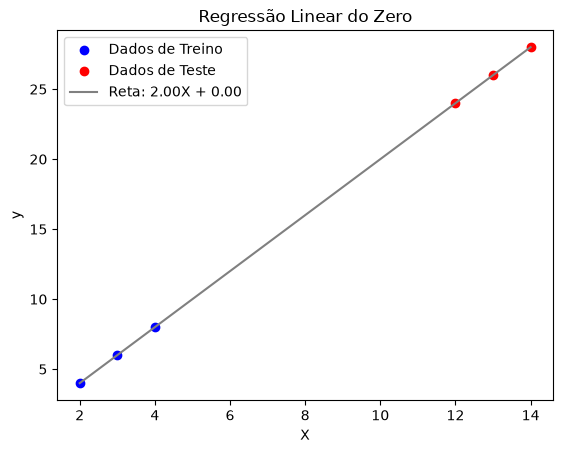

In [9]:
x_line = np.linspace(X_train.min(), X_test.max(), 100)
y_line = y_hat(x_line, w, b)

plt.scatter(X_train, y_train, color="blue", label="Dados de Treino")
plt.scatter(X_test, y_test, color="red", label="Dados de Teste")

plt.plot(x_line, y_line, color="grey", label=f"Reta: {w:.2f}X + {b:.2f}")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regressão Linear do Zero")
plt.legend()
plt.show()

Isso pode ser confirmado utilizando justamente o MSE:

In [10]:
def mse(X: np.ndarray, y: np.ndarray, weight: float, bias: float):
    return np.mean((y - y_hat(X, weight, bias)) ** 2)

y_pred = y_hat(X_test, w, b)

print(f"MSE de treino: {mse(X_train, y_train, w, b):.5f}")
print(f"MSE de teste: {mse(X_test, y_test, w, b):.5f}")

print("Valores reais:", y_test)
print("Previsões:", y_pred.round(2))

MSE de treino: 0.00000
MSE de teste: 0.00000
Valores reais: [24 26 28]
Previsões: [24. 26. 28.]
